In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# loading dataset
df = pd.read_csv(r'/content/drive/My Drive/Colab Notebooks/Feature Engineering/titanic.csv')
print(df)

print("Dataset loaded successfully!")

     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                                 ...     ...   ... 

In [ ]:
print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()


Dataset shape: (891, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
print("Dataset Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Description:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64



Survival Distribution:
Survived
0    549
1    342
Name: count, dtype: int64


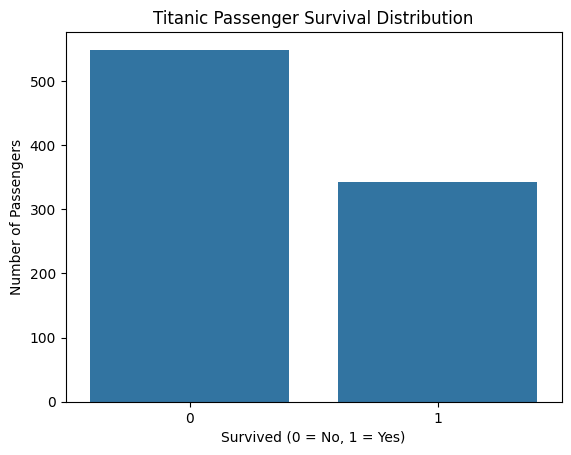

In [ ]:
print("\nSurvival Distribution:")
print(df['Survived'].value_counts())
sns.countplot(data=df, x='Survived')

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

In [ ]:
df = df.drop(   # Remove unnecessary columns
    columns=['PassengerId', 'Name', 'Ticket', 'Cabin']
)

# Separate features and target
X = df.drop('Survived', axis=1)
y = df['Survived']

# Identify numerical and categorical columns
numerical_features = [
    'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'
]

categorical_features = [
    'Sex', 'Embarked'
]
print("Features selected:")
print(X.columns.tolist())

print("\nTarget variable: Survived")

Features selected:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Target variable: Survived


In [ ]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Data preprocessing completed!")

print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])

Data preprocessing completed!
Training samples: 712
Testing samples: 179


In [ ]:
# Create SVM model
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,
    random_state=42
)

# Train the model
svm_model.fit(X_train_processed, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_processed)

print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

# Train the model
knn_model.fit(X_train_processed, y_train)

# Make predictions
knn_predictions = knn_model.predict(X_test_processed)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
models = {
    'SVM': svm_model,
    'KNN': knn_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test_processed)

    probabilities = model.predict_proba(X_test_processed)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average='weighted'
    )

    recall = recall_score(
        y_test, predictions, average='weighted'
    )

    f1 = f1_score(
        y_test, predictions, average='weighted'
    )

    loss = log_loss(
        y_test,
        probabilities,
        labels=model.classes_
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Loss': loss
    })

# Display results
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'Loss': '{:.4f}'
    })
)

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,Loss
0,SVM,0.8156,0.8163,0.8156,0.8112,0.4423
1,KNN,0.8156,0.8145,0.8156,0.8128,1.3637


In [ ]:
for name, model in models.items():

    predictions = model.predict(X_test_processed)

    print("\n", name, "CLASSIFICATION REPORT")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                'Did Not Survive',
                'Survived'
            ],
            zero_division=0
        )
    )


 SVM CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Did Not Survive       0.81      0.91      0.86       110
       Survived       0.82      0.67      0.74        69

       accuracy                           0.82       179
      macro avg       0.82      0.79      0.80       179
   weighted avg       0.82      0.82      0.81       179


 KNN CLASSIFICATION REPORT
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179



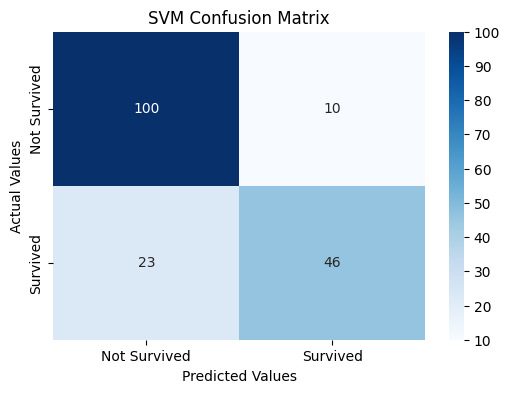

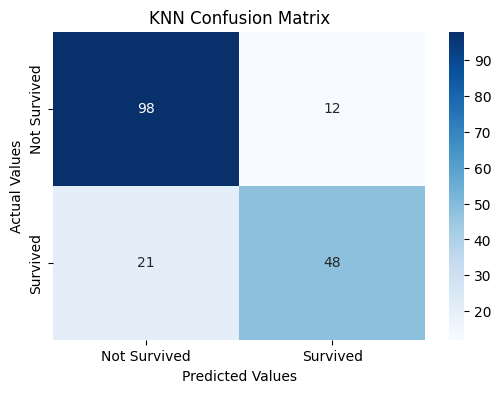